In [7]:
import os
import glob
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ase.io import read
from main.scripts.fitting_js.shell_functions import shells_from_model, shell_vectors
from fairchem.core import FAIRChemCalculator
from fairchem.core import pretrained_mlip

UMA_MODEL = "uma-s-1p1"
UMA_TASK = "omat" # task for bulk materials
MLIP_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
seed = np.random.randint(0, np.iinfo(np.int32).max, dtype=int)
predictor = pretrained_mlip.get_predict_unit(UMA_MODEL, device=MLIP_DEVICE, seed=seed)
calculator = FAIRChemCalculator(predictor, task_name=UMA_TASK)

unrelaxed_dir = "additional/fe-al-10/fe-al_mc_structures/final_structures"
relaxed_dir = "additional/fe-al-10/fe-al_relaxed_structures/final_structures"

In [8]:
import torch
import numpy as np

# =====================================================================
# PRECOMPUTATION (run once outside the loop)
# =====================================================================
NUM_SHELLS = 12
shell_keys, shell_distances = shells_from_model("main/scripts/fitting_js/model.txt", NUM_SHELLS)
vectors_of_shell = [shell_vectors(key) for key in shell_keys]

A_LATTICE = 2.867
SUPERCELL = 10
grid_n = 2 * SUPERCELL  # doubled grid so BCC half-integer sites land on integers

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# index tensors per shell, so each lookup below is one gather instead of a Python loop
shell_indices = []
for vectors in vectors_of_shell:
    vec_arr = np.array(vectors, dtype=np.int64) % grid_n  # wrap negative offsets for periodic indexing
    x_idx = torch.from_numpy(vec_arr[:, 0]).to(device)
    y_idx = torch.from_numpy(vec_arr[:, 1]).to(device)
    z_idx = torch.from_numpy(vec_arr[:, 2]).to(device)
    shell_indices.append((x_idx, y_idx, z_idx))

# =====================================================================
# MAIN PIPELINE
# =====================================================================
all_features = []
energy_values = []

unrelaxed_files = sorted(glob.glob(os.path.join(unrelaxed_dir, "*.cif")))
relaxed_files   = sorted(glob.glob(os.path.join(relaxed_dir, "*.cif")))
assert len(unrelaxed_files) == len(relaxed_files), "Directory file counts do not match!"
file_pairs = list(zip(unrelaxed_files, relaxed_files))

print(f'Starting multi-shell calculation pipeline on {device}...')

for idx, (unrelaxed_path, relaxed_path) in enumerate(file_pairs):
    # ---- features from the UNRELAXED structure (ideal lattice) ----
    atoms_unrelaxed = read(unrelaxed_path)

    # spin grid: +1 for Fe, -1 for Al, 0 on the empty (non-lattice) grid points
    grid = np.zeros((grid_n, grid_n, grid_n), dtype=np.float32)
    coords = np.round(atoms_unrelaxed.get_scaled_positions() * grid_n).astype(int) % grid_n
    symbols = np.array(atoms_unrelaxed.get_chemical_symbols())
    fe_coords, al_coords = coords[symbols == 'Fe'], coords[symbols == 'Al']
    grid[fe_coords[:, 0], fe_coords[:, 1], fe_coords[:, 2]] = 1.0
    grid[al_coords[:, 0], al_coords[:, 1], al_coords[:, 2]] = -1.0
    grid_tensor = torch.from_numpy(grid).to(device)

    # autocorrelation via FFT: corr[v] = sum over all pairs separated by v of s_i*s_j
    f_grid = torch.fft.fftn(grid_tensor)
    corr = torch.fft.ifftn(f_grid * torch.conj(f_grid)).real

    # sum over every vector in each shell; 0.5 because shell_vectors returns both v and -v
    all_features.append([(0.5 * corr[x, y, z].sum()).item() for x, y, z in shell_indices])

    # ---- energy target from the RELAXED structure ----
    # relaxation energy folds into the effective Js, mapped onto the parent lattice
    atoms_relaxed = read(relaxed_path)
    atoms_relaxed.calc = calculator
    with torch.no_grad():
        energy_values.append(float(atoms_relaxed.get_potential_energy()))

    if (idx + 1) % 30 == 0 or (idx + 1) == len(file_pairs):
        print(f' -> Processed {idx + 1}/{len(file_pairs)} frames...')

Starting multi-shell calculation pipeline on cpu...
 -> Processed 30/300 frames...
 -> Processed 60/300 frames...
 -> Processed 90/300 frames...
 -> Processed 120/300 frames...
 -> Processed 150/300 frames...
 -> Processed 180/300 frames...
 -> Processed 210/300 frames...
 -> Processed 240/300 frames...
 -> Processed 270/300 frames...
 -> Processed 300/300 frames...



        LSTSQ REGRESSION RESULTS (DYNAMIC)        
E0 = -15139.6218 eV  (reference energy)
J1 = 0.042015 eV   (shell 1)
J2 = 0.019651 eV   (shell 2)
J3 = -0.002044 eV   (shell 3)
J4 = -0.001405 eV   (shell 4)
J5 = 0.003775 eV   (shell 5)
J6 = 0.002208 eV   (shell 6)
J7 = 0.000222 eV   (shell 7)
J8 = 0.000486 eV   (shell 8)
J9 = -0.000096 eV   (shell 9)
J10 = -0.000390 eV   (shell 10)
J11 = -0.003213 eV   (shell 11)
J12 = 0.000659 eV   (shell 12)

Fit quality  R² = 0.9464
RMSE         = 418.24 meV


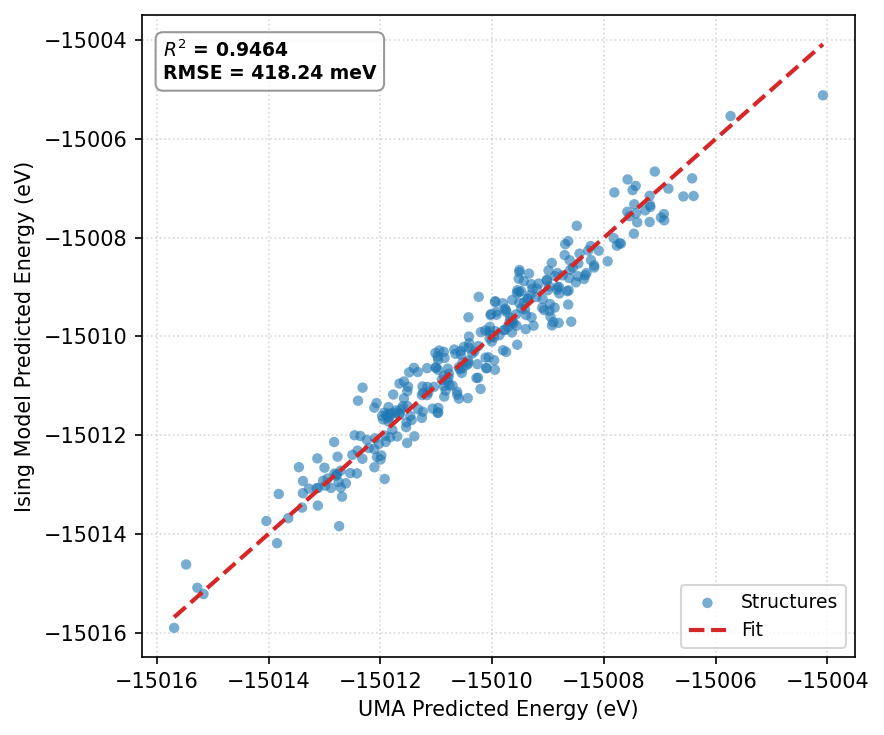

In [13]:
# =====================================================================
# LEAST SQUARES REGRESSION
# =====================================================================
# E = E0 + sum_n J_n * feature_n
features = np.array(all_features)                     # (n_configs, NUM_SHELLS)
y_fit    = np.array(energy_values)
X_fit    = np.column_stack([np.ones(len(y_fit)), features])   # column 0 is all 1s (Intercept E0), columns 1..N are the shell features

coeffs, *_ = np.linalg.lstsq(X_fit, y_fit, rcond=None)
E0_fit, J_fit = coeffs[0], coeffs[1:]  # Array of [J1, J2, J3...]

# Calculate R² Goodness of Fit
y_pred = X_fit @ coeffs
ss_res = np.sum((y_fit - y_pred) ** 2)
R2   = 1 - ss_res / np.sum((y_fit - y_fit.mean()) ** 2)
rmse = np.sqrt(ss_res / (len(y_fit) - X_fit.shape[1]))
J_sigma = rmse * np.sqrt(np.diag(np.linalg.inv(X_fit.T @ X_fit)))[1:]

# =====================================================================
# DISPLAY RESULTS
# =====================================================================
print("\n==================================================")
print("        LSTSQ REGRESSION RESULTS (DYNAMIC)        ")
print("==================================================")
print(f'E0 = {E0_fit:.4f} eV  (reference energy)')
for n, J in enumerate(J_fit):
    print(f'J{n+1} = {J:.6f} eV   (shell {n+1})')   
print(f'\nFit quality  R² = {R2:.4f}')
print(f'RMSE         = {np.sqrt(ss_res/len(y_fit))*1000:.2f} meV')
print("==================================================")

# =====================================================================
# DATA EXPORT
# =====================================================================
# Save configurations with their multi-shell vectors
df_results = pd.DataFrame({'CIF_File': [os.path.basename(f) for f in unrelaxed_files],
                           'Energy_eV': energy_values})
for n in range(NUM_SHELLS):
    df_results[f'SNS_T_Shell{n+1}'] = features[:, n]
df_results.to_csv('interaction_fit_data_multi.csv', index=False)

pd.DataFrame({'Parameter': ['E0'] + [f'J{n+1}' for n in range(NUM_SHELLS)],
              'Value_eV': [E0_fit] + list(J_fit)}).to_csv('fit_parameters_multi.csv', index=False)

# =====================================================================
# DYNAMIC PLOTTING (Predicted Energy vs. Actual Energy)
# =====================================================================
# Note: For multi-variable regression, we plot Predicted vs True Energy 
# since a simple 1D line cannot display multi-dimensional features.
plt.figure(figsize=(6, 5), dpi=150)

plt.scatter(y_fit, y_pred, color="#1f77b4", alpha=0.6, edgecolors="none", s=25, label="Structures")
ideal_line = [min(y_fit), max(y_fit)]
plt.plot(ideal_line, ideal_line, color="#d62728", linestyle="--", linewidth=2, label="Fit")

# plt.title("Cluster Expansion Multi-Shell Fit Accuracy", fontsize=11, fontweight="bold", pad=12)
plt.xlabel("UMA Predicted Energy (eV)", fontsize=10)
plt.ylabel("Ising Model Predicted Energy (eV)", fontsize=10)

plt.text(
    0.03, 0.90, f"$R^2$ = {R2:.4f}\nRMSE = {np.sqrt(ss_res/len(y_fit))*1000:.2f} meV", 
    transform=plt.gca().transAxes, fontsize=9, fontweight="bold",
    bbox=dict(facecolor="white", alpha=0.8, edgecolor="gray", boxstyle="round,pad=0.4")
)

plt.grid(True, linestyle=":", alpha=0.5)
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()